In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
import os
import tarfile
import urllib.request

DOWNLOAD_ROOT = "https://raw.githubusercontent.com/ageron/handson-ml2/master/"
HOUSING_PATH = os.path.join("datasets", "housing")
HOUSING_URL = DOWNLOAD_ROOT + "datasets/housing/housing.tgz"

def fetch_housing_data(housing_url=HOUSING_URL, housing_path=HOUSING_PATH):
    if not os.path.isdir(housing_path):
        os.makedirs(housing_path)
    tgz_path = os.path.join(housing_path, "housing.tgz")
    urllib.request.urlretrieve(housing_url, tgz_path)
    housing_tgz = tarfile.open(tgz_path)
    housing_tgz.extractall(path=housing_path)
    housing_tgz.close()


In [5]:
fetch_housing_data()

In [6]:
import pandas as pd

def load_housing_data(housing_path=HOUSING_PATH):
    csv_path = os.path.join(housing_path, "housing.csv")
    return pd.read_csv(csv_path)

In [7]:
housing = load_housing_data()
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [9]:
housing.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB


In [11]:
housing["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [12]:
housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


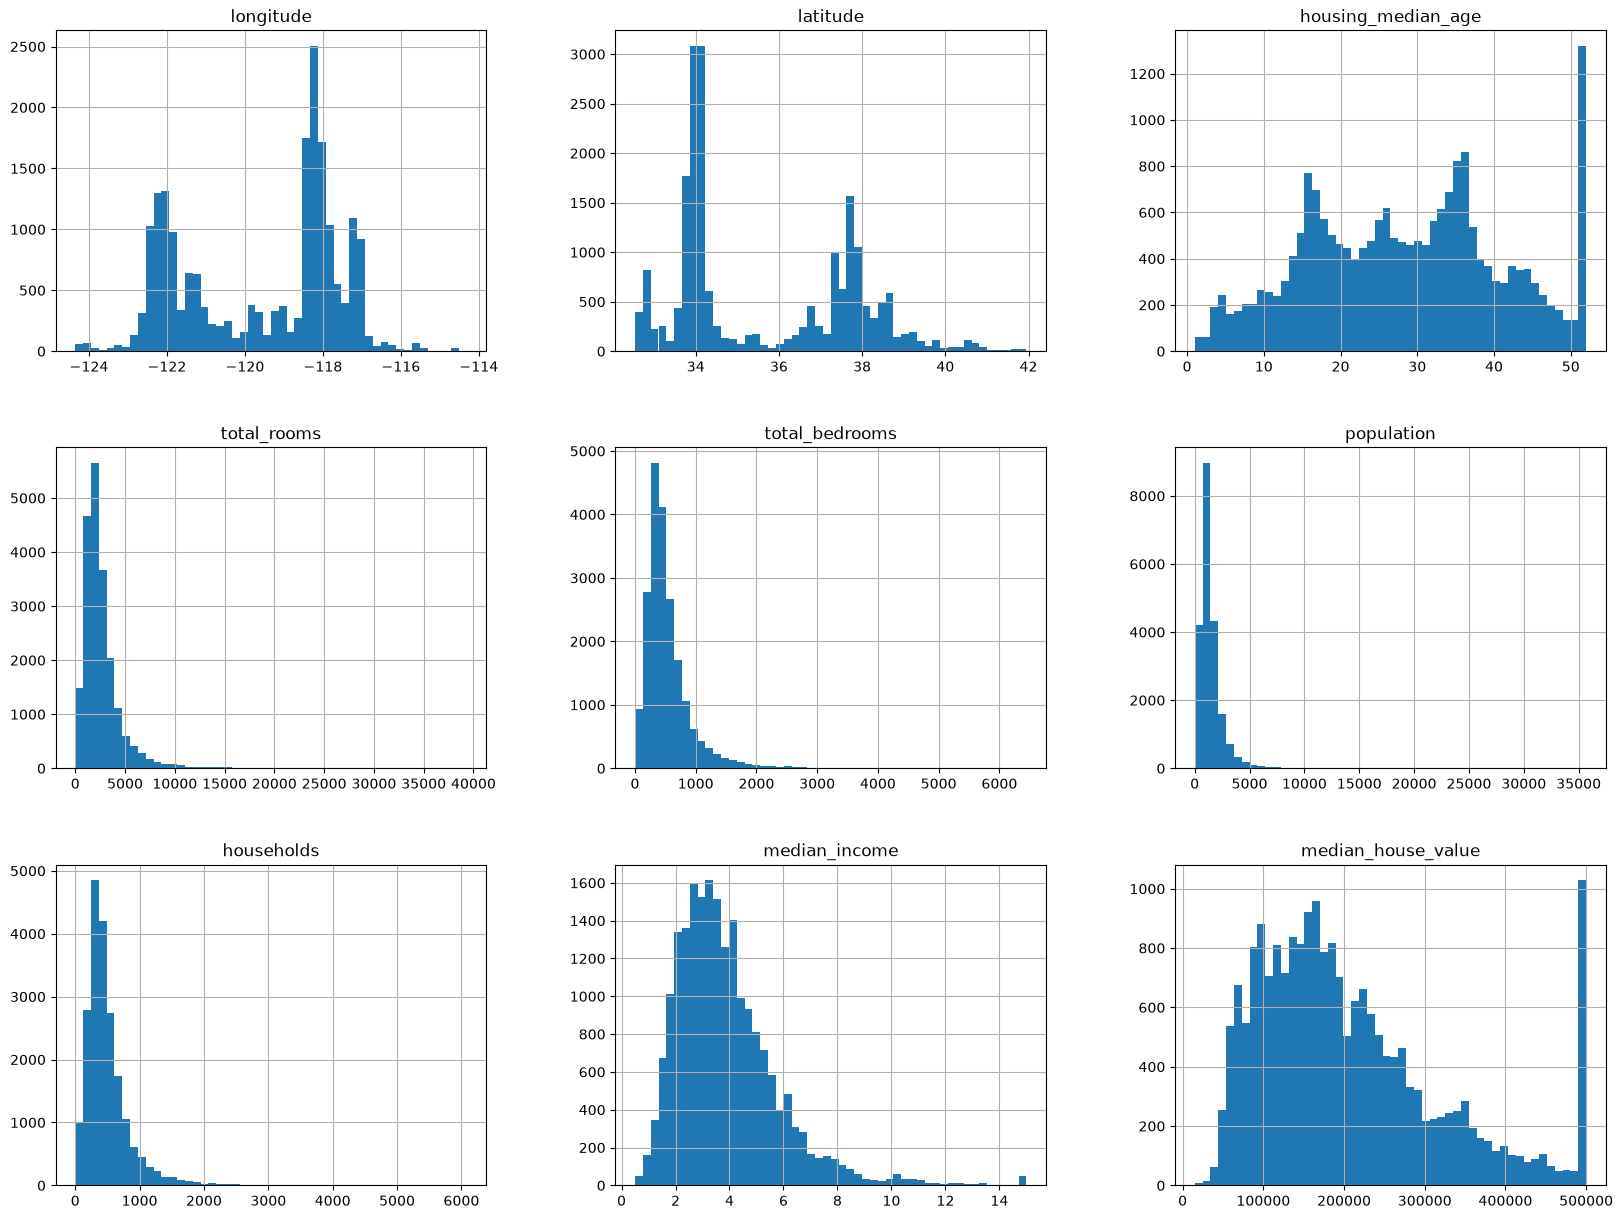

In [14]:
import matplotlib.pyplot as plt
housing.hist(bins=50, figsize=(20,15))
# save_fig("attribute_histogram_plots")
plt.show()

In [15]:
from sklearn.model_selection import train_test_split

train_set, test_set = train_test_split(
    housing,
    test_size=0.2,
    random_state=42
)

In [16]:
from sklearn.model_selection import StratifiedShuffleSplit

# Divide median income into five categories
housing["income_cat"] = pd.cut(
    housing["median_income"],
    bins=[0, 1.5, 3.0, 4.5, 6.0, np.inf],
    labels=[1, 2, 3, 4, 5]
)

# Create a stratified split
split = StratifiedShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

for train_index, test_index in split.split(
    housing, housing["income_cat"]
):
    strat_train_set = housing.loc[train_index]
    strat_test_set = housing.loc[test_index]

# Remove the temporary income category
strat_train_set = strat_train_set.drop("income_cat", axis=1)
strat_test_set = strat_test_set.drop("income_cat", axis=1)

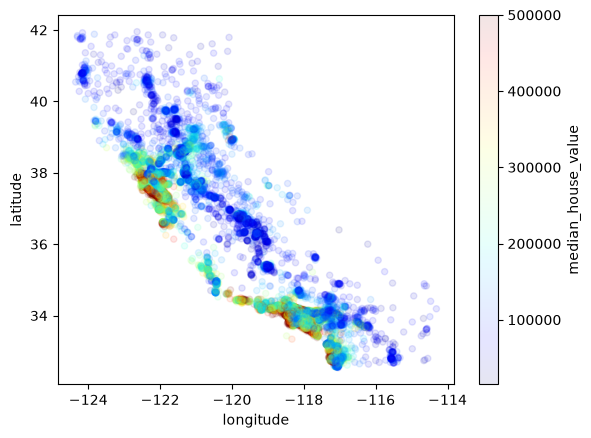

In [17]:
housing = strat_train_set.copy()

housing.plot(
    kind="scatter",
    x="longitude",
    y="latitude",
    alpha=0.1,
    c="median_house_value",
    cmap=plt.get_cmap("jet"),
    colorbar=True
)

plt.show()

In [18]:
corr_matrix = housing.corr(numeric_only=True)

print(
    corr_matrix["median_house_value"].sort_values(
        ascending=False
    )
)

median_house_value    1.000000
median_income         0.687151
total_rooms           0.135140
housing_median_age    0.114146
households            0.064590
total_bedrooms        0.047781
population           -0.026882
longitude            -0.047466
latitude             -0.142673
Name: median_house_value, dtype: float64


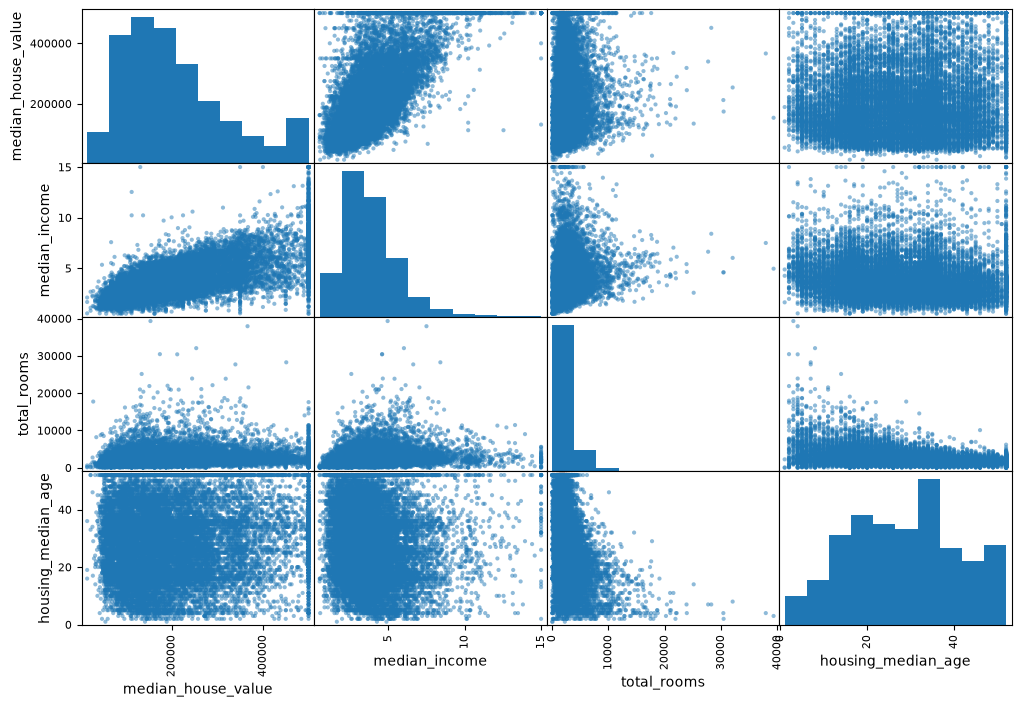

In [19]:
from pandas.plotting import scatter_matrix

attributes = [
    "median_house_value",
    "median_income",
    "total_rooms",
    "housing_median_age"
]

scatter_matrix(
    housing[attributes],
    figsize=(12, 8)
)

plt.show()

In [20]:
housing["rooms_per_household"] = (
    housing["total_rooms"] / housing["households"]
)

housing["bedrooms_per_room"] = (
    housing["total_bedrooms"] / housing["total_rooms"]
)

housing["population_per_household"] = (
    housing["population"] / housing["households"]
)

In [21]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

# Select numerical columns only
housing_num = housing.drop("ocean_proximity", axis=1)

# Learn the median of each numerical column
imputer.fit(housing_num)

# Replace missing values with the respective medians
X = imputer.transform(housing_num)

In [22]:
from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder()

housing_cat = housing[["ocean_proximity"]]

housing_cat_encoded = encoder.fit_transform(housing_cat)

print(housing_cat_encoded[:5])

[[1.]
 [4.]
 [1.]
 [4.]
 [0.]]


In [23]:
from sklearn.base import BaseEstimator, TransformerMixin
import numpy as np

# These positions match the numerical column order
rooms_ix = 3
bedrooms_ix = 4
population_ix = 5
households_ix = 6

class CombinedAttributesAdder(BaseEstimator, TransformerMixin):

    def __init__(self, add_bedrooms_per_room=True):
        self.add_bedrooms_per_room = add_bedrooms_per_room

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        # Calculate average rooms per household
        rooms_per_household = (
            X[:, rooms_ix] / X[:, households_ix]
        )

        # Calculate population per household
        population_per_household = (
            X[:, population_ix] / X[:, households_ix]
        )

        # Create a new column for bedrooms per room
        if self.add_bedrooms_per_room:
            bedrooms_per_room = (
                X[:, bedrooms_ix] / X[:, rooms_ix]
            )

            return np.c_[
                X,
                rooms_per_household,
                population_per_household,
                bedrooms_per_room
            ]

        return np.c_[
            X,
            rooms_per_household,
            population_per_household
        ]

In [24]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(housing_num)

In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_data = scaler.fit_transform(housing_num)

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("attribs_adder", CombinedAttributesAdder()),
    ("std_scaler", StandardScaler())
])

In [27]:
from sklearn.preprocessing import OneHotEncoder

cat_pipeline = Pipeline([
    ("one_hot", OneHotEncoder())
])

In [28]:
from sklearn.compose import ColumnTransformer

# Separate numerical and categorical column names
num_attribs = list(housing_num)
cat_attribs = ["ocean_proximity"]

full_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_attribs),
    ("cat", cat_pipeline, cat_attribs)
])

# Apply all preprocessing steps
housing_prepared = full_pipeline.fit_transform(housing)

print(housing_prepared.shape)

(16512, 20)


In [29]:
# Input features
housing = strat_train_set.drop(
    "median_house_value", axis=1
)

# Target value to predict
housing_labels = strat_train_set["median_house_value"].copy()

In [30]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np

lin_reg = LinearRegression()

# Train the model
lin_reg.fit(housing_prepared, housing_labels)

# Predict house values
housing_predictions = lin_reg.predict(housing_prepared)

# Calculate RMSE
lin_mse = mean_squared_error(
    housing_labels, housing_predictions
)

lin_rmse = np.sqrt(lin_mse)

print("Linear Regression RMSE:", lin_rmse)

Linear Regression RMSE: 1.8008732161702123e-10


In [31]:
from sklearn.tree import DecisionTreeRegressor

tree_reg = DecisionTreeRegressor(random_state=42)

tree_reg.fit(housing_prepared, housing_labels)

predictions = tree_reg.predict(housing_prepared)

tree_rmse = np.sqrt(
    mean_squared_error(housing_labels, predictions)
)

print("Decision Tree RMSE:", tree_rmse)

Decision Tree RMSE: 0.0


In [32]:
from sklearn.ensemble import RandomForestRegressor

forest_reg = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

forest_reg.fit(housing_prepared, housing_labels)

predictions = forest_reg.predict(housing_prepared)

forest_rmse = np.sqrt(
    mean_squared_error(housing_labels, predictions)
)

print("Random Forest RMSE:", forest_rmse)

Random Forest RMSE: 35.041937239165236


In [33]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    forest_reg,
    housing_prepared,
    housing_labels,
    scoring="neg_mean_squared_error",
    cv=10
)

# Convert negative MSE into positive RMSE
rmse_scores = np.sqrt(-scores)

print("Scores:", rmse_scores)
print("Mean RMSE:", rmse_scores.mean())
print("Standard Deviation:", rmse_scores.std())

Scores: [ 54.27077113  51.83004588  74.76275248 219.72724978  58.90412955
 111.02369265  73.88559158  54.57551495  45.0308596  123.27657979]
Mean RMSE: 86.72871873815609
Standard Deviation: 50.735505213199666


In [34]:
from sklearn.model_selection import GridSearchCV

param_grid = [
    {
        "n_estimators": [3, 10, 30],
        "max_features": [2, 4, 6, 8]
    },
    {
        "bootstrap": [False],
        "n_estimators": [3, 10],
        "max_features": [2, 3, 4]
    }
]

forest_reg = RandomForestRegressor(random_state=42)

grid_search = GridSearchCV(
    forest_reg,
    param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    return_train_score=True
)

# Search for the best combination
grid_search.fit(housing_prepared, housing_labels)

print("Best parameters:", grid_search.best_params_)
print("Best model:", grid_search.best_estimator_)

Best parameters: {'max_features': 8, 'n_estimators': 30}
Best model: RandomForestRegressor(max_features=8, n_estimators=30, random_state=42)


In [35]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_distributions = {
    "n_estimators": randint(10, 200),
    "max_features": randint(2, 8)
}

random_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42),
    param_distributions,
    n_iter=10,
    cv=5,
    scoring="neg_mean_squared_error",
    random_state=42
)

random_search.fit(housing_prepared, housing_labels)

print(random_search.best_params_)

{'max_features': 7, 'n_estimators': 139}


In [36]:
feature_importances = (
    grid_search.best_estimator_.feature_importances_
)

print(feature_importances)

[6.91463565e-03 7.79957027e-03 2.64232045e-03 1.18008161e-03
 9.02472952e-04 9.86476640e-04 9.02325003e-04 1.86616186e-01
 6.43017829e-01 7.49910134e-03 3.54547754e-03 1.47642075e-02
 1.02822658e-02 1.43572357e-02 1.44845332e-02 1.40116428e-03
 8.23936682e-02 3.96486175e-08 1.39109397e-04 1.71298996e-04]


In [37]:
from sklearn.pipeline import Pipeline
import joblib

# Combine preprocessing and the best model
final_model = Pipeline([
    ("preparation", full_pipeline),
    ("model", grid_search.best_estimator_)
])

# Train the complete pipeline on training data
final_model.fit(
    strat_train_set.drop("median_house_value", axis=1),
    housing_labels
)

ValueError: Some column names are not columns of the dataframe: {'rooms_per_household', 'population_per_household', 'bedrooms_per_room', 'median_house_value'}

In [ ]:
# Separate test input and target
X_test = strat_test_set.drop(
    "median_house_value", axis=1
)

y_test = strat_test_set["median_house_value"].copy()

# Predict using the complete pipeline
final_predictions = final_model.predict(X_test)

# Calculate RMSE
final_mse = mean_squared_error(
    y_test, final_predictions
)

final_rmse = np.sqrt(final_mse)

print("Final Test RMSE:", final_rmse)